### 5.1 – Gauss quadrature on (0,1) with geometric subintervals

#### (a) Mapping Gauss points on [a,b]

Let $t \in [-1,1]$ and define the affine map  
$$
x(t) = \frac{a+b}{2} + \frac{b-a}{2}t .
$$

Then  
$$
\int_a^b f(x)\,dx = \frac{b-a}{2}\int_{-1}^1 f\!\left(\frac{a+b}{2}+\frac{b-a}{2}t\right)\,dt .
$$

If $\{x_i^G,w_i^G\}_{i=1}^n$ are Gauss–Legendre nodes/weights on $[-1,1]$,  
then the mapped nodes on $[a,b]$ are  
$$
x_i^{G,a,b} = \frac{a+b}{2} + \frac{b-a}{2}\,x_i^G ,
$$
and the rule becomes  
$$
\int_a^b f(x)\,dx \approx \frac{b-a}{2}\sum_{i=1}^n w_i^G\, f(x_i^{G,a,b}) .
$$

---

#### (b) Composite Gauss rule on (0,1)

Use $L$ subintervals  
$$
(0,q^{L-1}),\ (q^{L-1},q^{L-2}),\ \ldots,\ (q,1),
$$
apply the $n$-point Gauss rule on each, mapping nodes by (a).  
The subinterval contribution is  
$$
\frac{b-a}{2}\sum_{i=1}^n w_i^G\, f\!\left(\tfrac{a+b}{2}+\tfrac{b-a}{2}x_i^G\right),
$$
and the total is the sum over all subintervals.

Check with $f(x)=x^m$, $m=0,1,2$ to verify exactness.

---

#### (c) Error study for $f(x)=x^{0.1}\log x$

We use  
$$
\int_0^1 x^\alpha \log x\,dx = -\frac{1}{(\alpha+1)^2},\qquad \alpha>-1.
$$

So with $\alpha=0.1$, the exact integral is $-1/1.1^2$.

We compute errors for $n=L=1,\dots,20$ and $q\in\{0.5,0.15,0.05\}$  
and plot a semilog curve of error vs. $n$.

---

#### (d) Fit the error to $C e^{-bn}$

We fit  
$$
\log(\text{error}) \approx \log C - b n
$$
(using `numpy.polyfit`) to obtain $C$ and $b$.  
The largest $b$ indicates the fastest exponential decay (best $q$).


Polynomial checks (f(x)=x^m):
 m  n  L   q   approx    exact      abs_err
 0  1  1 0.5 1.000000 1.000000 0.000000e+00
 0  1  2 0.5 1.000000 1.000000 0.000000e+00
 0  1  5 0.5 1.000000 1.000000 0.000000e+00
 0  2  1 0.5 1.000000 1.000000 0.000000e+00
 0  2  2 0.5 1.000000 1.000000 0.000000e+00
 0  2  5 0.5 1.000000 1.000000 0.000000e+00
 0  3  1 0.5 1.000000 1.000000 2.220446e-16
 0  3  2 0.5 1.000000 1.000000 2.220446e-16
 0  3  5 0.5 1.000000 1.000000 2.220446e-16
 1  1  1 0.5 0.500000 0.500000 0.000000e+00
 1  1  2 0.5 0.500000 0.500000 0.000000e+00
 1  1  5 0.5 0.500000 0.500000 0.000000e+00
 1  2  1 0.5 0.500000 0.500000 0.000000e+00
 1  2  2 0.5 0.500000 0.500000 0.000000e+00
 1  2  5 0.5 0.500000 0.500000 0.000000e+00
 1  3  1 0.5 0.500000 0.500000 1.110223e-16
 1  3  2 0.5 0.500000 0.500000 1.110223e-16
 1  3  5 0.5 0.500000 0.500000 1.110223e-16
 2  1  1 0.5 0.250000 0.333333 8.333333e-02
 2  1  2 0.5 0.312500 0.333333 2.083333e-02
 2  1  5 0.5 0.321411 0.333333 1.192220e-02
 2

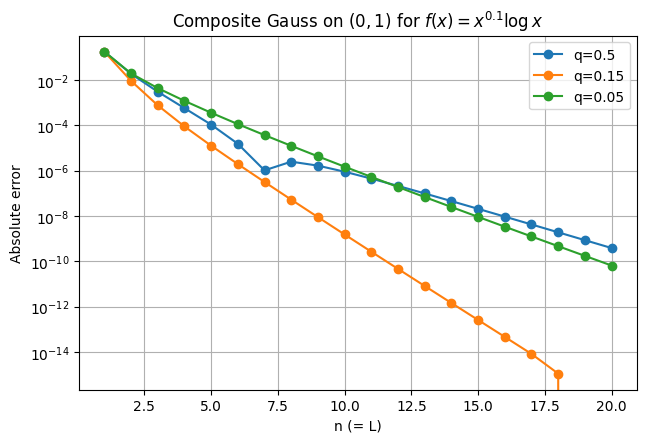


Exponential fit of errors (error ≈ C·e^{-b n}):
   q  C (fit)  b (fit)  RMS relative misfit  final error (n=20)
0.15 0.099633 1.784111             0.157393        0.000000e+00
0.05 0.064216 1.047411             0.166919        6.540901e-11
0.50 0.004701 0.830741             3.006637        3.868034e-10

Best q at n=20 (smallest error): q=0.15, error=0.000e+00


In [1]:
# Gauss composite quadrature on (0, 1) with geometric subintervals
# and error study for f(x) = x**0.1 * log(x).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

# ---------- (a) affine mapping ----------
def map_to_interval(a, b, t):
    """Map t in [-1,1] to x in [a,b]."""
    return (a + b) / 2.0 + (b - a) / 2.0 * t

# ---------- (b) composite Gauss ----------
def composite_gauss(n, L, q, f):
    """
    Approximate ∫_0^1 f(x) dx using a composite n-point Gauss rule
    over subintervals (0,q^(L-1)), (q^(L-1),q^(L-2)), ..., (q,1).
    """
    # Nodes/weights on [-1,1]
    nodes, weights = leggauss(n)

    # Build boundaries: [0, q^(L-1), q^(L-2), ..., q, 1]
    bounds = [0.0] + ([q**k for k in range(L-1, 0, -1)] if L > 1 else []) + [1.0]
    bounds = np.array(bounds, dtype=float)

    total = 0.0
    for a, b in zip(bounds[:-1], bounds[1:]):
        x_sub = map_to_interval(a, b, nodes)         # map nodes to [a,b]
        total += (b - a) / 2.0 * np.dot(weights, f(x_sub))  # scale weights
    return total

# ---------- quick polynomial check for part (b) ----------
def check_polynomials():
    rows = []
    for m in [0, 1, 2]:
        f = lambda x, m=m: x**m
        exact = 1.0 / (m + 1.0)
        for n in [1, 2, 3]:
            for L in [1, 2, 5]:
                approx = composite_gauss(n=n, L=L, q=0.5, f=f)
                rows.append({"m": m, "n": n, "L": L, "q": 0.5,
                             "approx": approx, "exact": exact,
                             "abs_err": abs(approx - exact)})
    return pd.DataFrame(rows)

poly_df = check_polynomials()
print("Polynomial checks (f(x)=x^m):")
print(poly_df.to_string(index=False))

# ---------- (c) error study for f(x)=x^0.1 log x ----------
def f_singular(x):
    """Vectorized f(x)=x^0.1 * log(x) with limit 0 at x=0."""
    out = np.zeros_like(x, dtype=float)
    mask = x > 0
    out[mask] = np.power(x[mask], 0.1) * np.log(x[mask])
    return out

def exact_integral_alpha_log(alpha=0.1):
    # ∫_0^1 x^a log(x) dx = -1/(a+1)^2
    return -1.0 / (1.0 + alpha) ** 2

def run_error_study(q_values=(0.5, 0.15, 0.05), nmax=20):
    I_exact = exact_integral_alpha_log(0.1)
    results = {}  # q -> (ns, errors)
    for q in q_values:
        ns, errs = [], []
        for n in range(1, nmax + 1):
            approx = composite_gauss(n=n, L=n, q=q, f=f_singular)
            ns.append(n)
            errs.append(abs(approx - I_exact))
        results[q] = (np.array(ns), np.array(errs))
    return I_exact, results

I_exact, results = run_error_study()
print(f"\nExact integral ∫_0^1 x^0.1 log(x) dx = {I_exact:.12f}")

# Plot semilog error vs n for each q
plt.figure(figsize=(7.2, 4.6))
for q, (ns, errs) in results.items():
    plt.semilogy(ns, errs, marker='o', label=f"q={q}")
plt.xlabel("n (= L)")
plt.ylabel("Absolute error")
plt.title(r"Composite Gauss on $(0,1)$ for $f(x)=x^{0.1}\log x$")
plt.grid(True, which="both")
plt.legend()
plt.show()

# ---------- (d) Fit error ≈ C e^{-b n} using polyfit ----------
fit_rows = []
for q, (ns, errs) in results.items():
    mask = (errs > 0) & (ns >= 3)                 # avoid zeros and tiny n
    n_fit = ns[mask].astype(float)
    y = np.log(errs[mask])
    m, c = np.polyfit(n_fit, y, 1)                # y ≈ m*n + c
    b = -m
    C = np.exp(c)
    pred = C * np.exp(-b * n_fit)
    rms_rel = np.sqrt(np.mean(((errs[mask] - pred) / errs[mask])**2))
    fit_rows.append({"q": q, "C (fit)": C, "b (fit)": b,
                     "RMS relative misfit": rms_rel,
                     "final error (n=20)": errs[-1]})

fit_df = pd.DataFrame(fit_rows).sort_values(by="b (fit)", ascending=False)
print("\nExponential fit of errors (error ≈ C·e^{-b n}):")
print(fit_df.to_string(index=False))

best_q = min(results.keys(), key=lambda q: results[q][1][-1])
print(f"\nBest q at n=20 (smallest error): q={best_q}, error={results[best_q][1][-1]:.3e}")


### 5.3 — Relative conditioning of multiplication, division, and square root

We study the **relative condition number**

$$
\kappa_{\text{rel}} = \frac{|\Delta f / f|}{\text{relative size of input perturbation}} .
$$

---

#### (a) Multiplication  $f(x,y) = x\,y$

Differential: $df = y\,dx + x\,dy$.

Hence

$$
\frac{|df|}{|f|} = \frac{|y\,dx + x\,dy|}{|x y|}
  \le \frac{|dx|}{|x|} + \frac{|dy|}{|y|}.
$$

- With 1-norm relative error:  $\kappa_{\text{rel}} = 1$  
- With ∞-norm relative error:  $\kappa_{\text{rel}} \le 2$

Multiplication is **well conditioned**.

---

#### (b) Division  $f(x,y) = \dfrac{x}{y}$  (with $y \neq 0$)

Differential:  $df = \dfrac{1}{y}\,dx - \dfrac{x}{y^2}\,dy$.

Then

$$
\frac{|df|}{|f|} = \left|\frac{dx}{x} - \frac{dy}{y}\right|
  \le \frac{|dx|}{|x|} + \frac{|dy|}{|y|}.
$$

- With 1-norm relative error:  $\kappa_{\text{rel}} = 1$  
- With ∞-norm relative error:  $\kappa_{\text{rel}} \le 2$

Division is also **well conditioned**.

---

#### (c) Square root  $f(x) = \sqrt{x}$  for $x>0$

Differential:  $df = \dfrac{1}{2\sqrt{x}}\,dx$.

So

$$
\frac{|df|}{|f|} = \frac{1}{2}\,\frac{|dx|}{|x|},
$$

and therefore

$$
\kappa_{\text{rel}}(x) = \tfrac{1}{2}.
$$

The square root is **well conditioned in the relative sense**  
(although **absolutely ill-conditioned** as $x \to 0^+$ because $|f'(x)|$ blows up).


Multiplication:
  max amp (∞-norm): 1.9999   [theory ≤ 2]
  max amp (1-norm): 1.0000     [theory ≤ 1]

Division:
  max amp (∞-norm): 1.9999   [theory ≤ 2]
  max amp (1-norm): 1.0000     [theory ≤ 1]

Square root:
  mean amp ≈ 0.5000   [theory = 0.5]
  median amp ≈ 0.5000



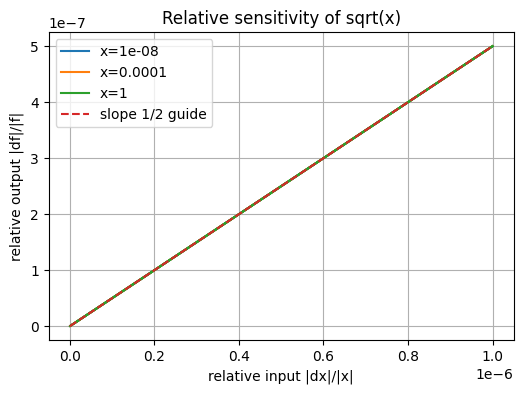

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def rel_err(a, a_tilde):
    """Compute relative error safely."""
    a = np.asarray(a, dtype=float)
    a_tilde = np.asarray(a_tilde, dtype=float)
    mask = (a != 0)
    out = np.zeros_like(a)
    out[mask] = np.abs(a_tilde[mask] - a[mask]) / np.abs(a[mask])
    return out

# ----------------------------------------------------------
# (a) Multiplication: z = x*y
# ----------------------------------------------------------
def test_multiplication(samples=20000, eps=1e-8):
    x = 10**rng.uniform(-4, 4, size=samples) * rng.choice([-1,1], size=samples)
    y = 10**rng.uniform(-4, 4, size=samples) * rng.choice([-1,1], size=samples)
    z = x*y

    ex = rng.uniform(-eps, eps, size=samples)
    ey = rng.uniform(-eps, eps, size=samples)

    z_t = (x*(1+ex)) * (y*(1+ey))

    out_rel = rel_err(z, z_t)
    in_rel_inf = np.maximum(np.abs(ex), np.abs(ey))
    in_rel_1 = np.abs(ex) + np.abs(ey)

    print("Multiplication:")
    print(f"  max amp (∞-norm): {np.max(out_rel/in_rel_inf):.4f}   [theory ≤ 2]")
    print(f"  max amp (1-norm): {np.max(out_rel/in_rel_1):.4f}     [theory ≤ 1]\n")

test_multiplication()

# ----------------------------------------------------------
# (b) Division: z = x/y
# ----------------------------------------------------------
def test_division(samples=20000, eps=1e-8):
    x = 10**rng.uniform(-4, 4, size=samples) * rng.choice([-1,1], size=samples)
    y = 10**rng.uniform(-4, 4, size=samples) * rng.choice([-1,1], size=samples)
    y[np.abs(y)<1e-12] = 1e-12  # avoid 0
    z = x/y

    ex = rng.uniform(-eps, eps, size=samples)
    ey = rng.uniform(-eps, eps, size=samples)

    z_t = (x*(1+ex)) / (y*(1+ey))

    out_rel = rel_err(z, z_t)
    in_rel_inf = np.maximum(np.abs(ex), np.abs(ey))
    in_rel_1 = np.abs(ex) + np.abs(ey)

    print("Division:")
    print(f"  max amp (∞-norm): {np.max(out_rel/in_rel_inf):.4f}   [theory ≤ 2]")
    print(f"  max amp (1-norm): {np.max(out_rel/in_rel_1):.4f}     [theory ≤ 1]\n")

test_division()

# ----------------------------------------------------------
# (c) Square root: f(x)=sqrt(x)
# ----------------------------------------------------------
def test_sqrt(samples=10000, eps=1e-8):
    x = 10**rng.uniform(-10, 6, size=samples)
    f = np.sqrt(x)

    ex = rng.uniform(-eps, eps, size=samples)
    f_t = np.sqrt(x*(1+ex))

    out_rel = rel_err(f, f_t)
    in_rel = np.abs(ex)
    ratio = out_rel / np.maximum(in_rel, 1e-300)

    print("Square root:")
    print(f"  mean amp ≈ {np.mean(ratio):.4f}   [theory = 0.5]")
    print(f"  median amp ≈ {np.median(ratio):.4f}\n")

    # visualize slope ~1/2
    xs = [1e-8, 1e-4, 1.0]
    plt.figure(figsize=(6,4))
    for xv in xs:
        ex_line = np.linspace(-1e-6, 1e-6, 101)
        rel_in = np.abs(ex_line)
        rel_out = np.abs(np.sqrt(xv*(1+ex_line)) - np.sqrt(xv)) / np.sqrt(xv)
        plt.plot(rel_in, rel_out, label=f"x={xv:g}")
    plt.plot([0,1e-6], [0,0.5e-6], '--', label="slope 1/2 guide")
    plt.xlabel("relative input |dx|/|x|")
    plt.ylabel("relative output |df|/|f|")
    plt.title("Relative sensitivity of sqrt(x)")
    plt.legend()
    plt.grid(True)
    plt.show()

test_sqrt()


### 5.4 — Legendre-type polynomials $L_n(x) := \left(\dfrac{d}{dx}\right)^n (x^2-1)^n$

> Note: $L_n$ equals the classical Legendre polynomial $P_n$ up to a positive constant factor ($L_n = 2^n n! \, P_n$). All statements below are unaffected by that constant.

---

#### (a) Parity of $L_n$

The seed $(x^2-1)^n$ is an **even** function of $x$.  
Differentiating an even function gives an odd function, and differentiating an odd function gives an even function.  
After $n$ derivatives the parity matches $n$:
- $n$ even $\Rightarrow L_n$ even,
- $n$ odd  $\Rightarrow L_n$ odd.

So **$L_n$ is even for even $n$ and odd for odd $n$**.

---

#### (b) Endpoint roots of $L_n^{(\ell)}(x) := \left(\dfrac{d}{dx}\right)^{\ell} (x^2-1)^n$, $0 \le \ell < n$

The polynomial $(x^2-1)^n$ has roots at $x=\pm1$ of multiplicity $n$.  
Taking $\ell<n$ derivatives can reduce (but not remove) these multiplicities by at most $\ell$, hence each endpoint still has multiplicity at least $n-\ell \ge 1$. Therefore
$$
L_n^{(\ell)}(\pm1)=0 \qquad \text{for } 0\le \ell < n.
$$

---

#### (c) Orthogonality: $\displaystyle \int_{-1}^1 L_n(x)\,q(x)\,dx=0$ for all $q\in\Pi_{n-1}$

Write $L_n(x)=\left(\dfrac{d}{dx}\right)^n (x^2-1)^n$ and integrate by parts $n$ times:
$$
\int_{-1}^1 L_n\,q\,dx
= \int_{-1}^1 \frac{d^n}{dx^n}(x^2-1)^n \, q \, dx
= (-1)^n \int_{-1}^1 (x^2-1)^n \, q^{(n)}(x)\,dx + \Big[\text{boundary terms}\Big].
$$
The **boundary terms vanish** because at each step one factor $(x^2-1)^{n-k}$ remains and equals $0$ at $x=\pm1$ for $k<n$.  
Since $\deg q \le n-1$, we have $q^{(n)}\equiv 0$, hence the integral is $0$.

---

#### (d) Gauss points from roots of $L_{n+1}$ and exactness up to degree $2n+1$

Let $x_0,\dots,x_n$ be the $n+1$ roots of $L_{n+1}$.  
Let $I_n$ denote the degree-$\le n$ interpolant at these nodes.  
For any $q\in\Pi_{2n+1}$, the interpolation error is divisible by $\prod_{j=0}^n (x-x_j)$:
$$
q(x)-I_n(q)(x) = \Big(\prod_{j=0}^n (x-x_j)\Big)\, r(x),
$$
where $\deg r \le 2n+1-(n+1)=n$. Up to a constant,
$$
\prod_{j=0}^n (x-x_j) \propto L_{n+1}(x).
$$
Therefore
$$
\int_{-1}^1 \big(q - I_n(q)\big)\,dx
= c \int_{-1}^1 L_{n+1}(x)\, r(x)\,dx = 0,
$$
by part (c) with $n\mapsto n+1$ (since $\deg r \le n$). Hence
$$
\int_{-1}^1 I_n(q)\,dx = \int_{-1}^1 q\,dx \qquad \text{for all } q\in\Pi_{2n+1}.
$$
Thus, the roots of $L_{n+1}$ are the **Gauss–Legendre nodes** and the corresponding quadrature with $n+1$ points is **exact up to degree $2n+1$**.


Endpoint values for n=4 (should be 0 for ell=0..3):
  ell=0:  L_n^(ell)(-1)=0,  L_n^(ell)(1)=0
  ell=1:  L_n^(ell)(-1)=0,  L_n^(ell)(1)=0
  ell=2:  L_n^(ell)(-1)=0,  L_n^(ell)(1)=0
  ell=3:  L_n^(ell)(-1)=0,  L_n^(ell)(1)=0


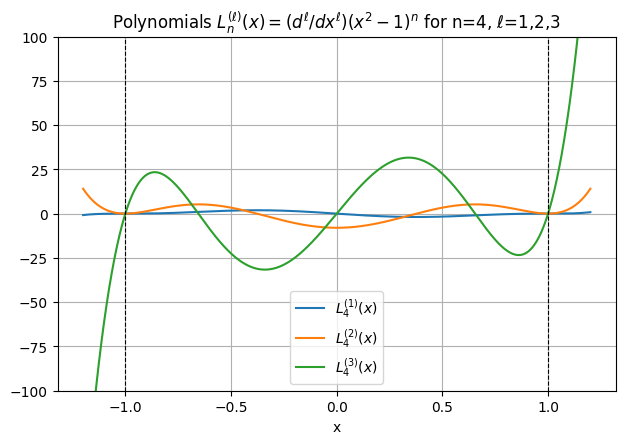

Parity check n=0:  L_n(-x) = (-1)^0 L_n(x)?  -> True
Parity check n=1:  L_n(-x) = (-1)^1 L_n(x)?  -> True
Parity check n=2:  L_n(-x) = (-1)^2 L_n(x)?  -> True
Parity check n=3:  L_n(-x) = (-1)^3 L_n(x)?  -> True
Parity check n=4:  L_n(-x) = (-1)^4 L_n(x)?  -> True
Parity check n=5:  L_n(-x) = (-1)^5 L_n(x)?  -> True
Parity check n=6:  L_n(-x) = (-1)^6 L_n(x)?  -> True


In [5]:
# Build L_n(x) = d^n/dx^n (x^2-1)^n and its lower derivatives,
# verify endpoint zeros for l<n, and plot for n=4, l=1,2,3.

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

x = sp.symbols('x')

def L_n_symbolic(n):
    """Return sympy polynomial for L_n(x) := (d/dx)^n (x^2-1)^n."""
    base = (x**2 - 1)**n
    return sp.diff(base, x, n).expand()

def L_n_ell_symbolic(n, ell):
    """Return L_n^{(ell)}(x) := (d/dx)^ell (x^2-1)^n."""
    return sp.diff((x**2 - 1)**n, x, ell).expand()

# ---- (b) Endpoint zeros check for general n ----
def check_endpoints(n):
    rows = []
    for ell in range(0, n):
        poly = L_n_ell_symbolic(n, ell)
        val_m1 = sp.N(poly.subs(x, -1))
        val_p1 = sp.N(poly.subs(x, 1))
        rows.append((ell, val_m1, val_p1))
    return rows

n = 4
print(f"Endpoint values for n={n} (should be 0 for ell=0..{n-1}):")
for ell, vm1, vp1 in check_endpoints(n):
    print(f"  ell={ell}:  L_n^(ell)(-1)={vm1},  L_n^(ell)(1)={vp1}")

# ---- Plot for n=4, ell=1,2,3 ----
ells = [1, 2, 3]
xs = np.linspace(-1.2, 1.2, 800)
plt.figure(figsize=(7.2, 4.6))

for ell in ells:
    poly = L_n_ell_symbolic(n, ell)
    f = sp.lambdify(x, poly, 'numpy')
    plt.plot(xs, f(xs), label=f"$L_{{{n}}}^{{({ell})}}(x)$")

plt.axvline(-1, color='k', linestyle='--', linewidth=0.8)
plt.axvline(1, color='k', linestyle='--', linewidth=0.8)
plt.ylim(-100, 100)
plt.grid(True)
plt.legend()
plt.title(f"Polynomials $L_n^{{(\\ell)}}(x) = (d^\\ell/dx^\\ell)(x^2-1)^n$ for n={n}, ℓ=1,2,3")
plt.xlabel("x")
plt.show()

# ---- (a) Parity demo: show L_n(-x) = (-1)^n L_n(x) for n=0..6 ----
for n in range(7):
    Ln = L_n_symbolic(n)
    parity = sp.simplify(Ln.subs(x, -x) - (-1)**n * Ln)
    ok = (parity == 0)
    print(f"Parity check n={n}:  L_n(-x) = (-1)^{n} L_n(x)?  -> {ok}")


### 5.5 — The function $ \varphi(x) = \sqrt{x+1} - \sqrt{x} $

#### (a) Relative conditioning for large $x$

Compute the derivative:

$$
\varphi'(x) = \frac{1}{2\sqrt{x+1}} - \frac{1}{2\sqrt{x}}
= \frac{\sqrt{x} - \sqrt{x+1}}{2\sqrt{x}\sqrt{x+1}}
= -\frac{\varphi(x)}{2\sqrt{x}\sqrt{x+1}}.
$$

The (scalar) **relative condition number** is

$$
\kappa_{\mathrm{rel}}(x)
= \left| \frac{x\,\varphi'(x)}{\varphi(x)} \right|
= \frac{x}{2\sqrt{x}\sqrt{x+1}}
= \frac{\sqrt{x}}{2\sqrt{x+1}}
\;\xrightarrow[x\to\infty]{}\; \frac{1}{2}.
$$

Thus, **in relative terms $ \varphi $ is well conditioned** for large $x$
(bounded condition number $\to 1/2$).

However, the direct computation $ \sqrt{x+1} - \sqrt{x} $ suffers from **catastrophic cancellation** when $x$ is large, so it is **numerically unstable**.

---

#### (b) Stable numerical realization

Rationalize the difference:

$$
\varphi(x)
= \frac{(\sqrt{x+1}-\sqrt{x})(\sqrt{x+1}+\sqrt{x})}{\sqrt{x+1}+\sqrt{x}}
= \frac{(x+1)-x}{\sqrt{x+1}+\sqrt{x}}
= \frac{1}{\sqrt{x+1}+\sqrt{x}}.
$$

This expression avoids subtraction of nearly equal quantities and is **numerically stable** for large $x$.
